# Loi d’Okun au Maroc — Régression linéaire simple

**Algorithme n° 1 : Régression linéaire (Simple Linear Regression)**  
**Objectif :** étudier la relation entre la croissance du PIB réel et la variation annuelle du taux de chômage au Maroc.

## Spécification retenue
\[
\Delta U_t = \alpha + \beta g_t + \varepsilon_t
\]

- \(\Delta U_t = U_t-U_{t-1}\) : variation annuelle du taux de chômage, en points de pourcentage.
- \(g_t\) : taux de croissance annuel du PIB réel, en %.
- \(\beta\) : coefficient d’Okun estimé. Le signe attendu est négatif.

**Données :** Banque mondiale, indicateurs `NY.GDP.MKTP.KD.ZG` et `SL.UEM.TOTL.ZS`, Maroc.  
La série de chômage commence une année avant la période d’analyse afin de calculer sa première différence. Le notebook télécharge les données directement depuis l’API officielle de la Banque mondiale au moment de l’exécution.

> Les résultats numériques ne sont pas préremplis : ils sont calculés à partir des données effectivement téléchargées, afin d’éviter toute donnée ou performance inventée.


In [1]:
!pip -q install pandas numpy matplotlib requests statsmodels scikit-learn

In [2]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

COUNTRY = "MAR"
START_YEAR = 1990   # année supplémentaire pour calculer Δ chômage en 1991
END_YEAR = 2024     # période d'étude principale jusqu'en 2024

INDICATORS = {
    "gdp_growth": "NY.GDP.MKTP.KD.ZG",
    "unemployment": "SL.UEM.TOTL.ZS"
}

def get_world_bank_series(indicator, country=COUNTRY, start=START_YEAR, end=END_YEAR):
    url = (
        f"https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
        f"?date={start}:{end}&format=json&per_page=200"
    )
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    payload = response.json()
    if len(payload) < 2 or payload[1] is None:
        raise ValueError(f"Aucune donnée reçue pour {indicator}. Vérifier la connexion ou l'indicateur.")
    data = pd.DataFrame(payload[1])[["date", "value"]]
    data["year"] = data["date"].astype(int)
    data[indicator] = pd.to_numeric(data["value"], errors="coerce")
    return data[["year", indicator]]

gdp = get_world_bank_series(INDICATORS["gdp_growth"]).rename(
    columns={INDICATORS["gdp_growth"]: "gdp_growth"}
)
unemp = get_world_bank_series(INDICATORS["unemployment"]).rename(
    columns={INDICATORS["unemployment"]: "unemployment"}
)

df = gdp.merge(unemp, on="year", how="inner").sort_values("year")
df["delta_unemployment"] = df["unemployment"].diff()
df = df[(df["year"] >= START_YEAR + 1) & (df["year"] <= END_YEAR)]
df = df.dropna(subset=["gdp_growth", "delta_unemployment"]).reset_index(drop=True)

print("Nombre d'observations :", len(df))
print("Période :", int(df.year.min()), "-", int(df.year.max()))
display(df.head())
display(df.tail())


Nombre d'observations : 33
Période : 1992 - 2024


,year,gdp_growth,unemployment,delta_unemployment
0,1992,-2.097739,13.781,0.279
1,1993,-0.740592,14.026,0.245
2,1994,10.588000,13.858,-0.168
3,1995,-5.405448,14.054,0.196
4,1996,12.372876,13.362,-0.692


,year,gdp_growth,unemployment,delta_unemployment
28,2020,-7.178207,11.189,1.998
29,2021,8.154739,10.551,-0.638
30,2022,1.812692,9.413,-1.138
31,2023,3.655644,8.896,-0.517
32,2024,3.793365,9.103,0.207


## 1. Description et qualité des données

Les deux séries sont annuelles. Le taux de chômage est exprimé en pourcentage de la population active ; sa première différence est exprimée en points de pourcentage. La croissance du PIB est un taux annuel en pourcentage.

Valeurs manquantes :


,Nombre
year,0
gdp_growth,0
unemployment,0
delta_unemployment,0


Doublons : 0


,gdp_growth,unemployment,delta_unemployment
count,33.000000,33.000000,33.000000
mean,3.508172,10.941515,-0.133303
std,3.981521,1.981323,0.647233
min,-7.178207,8.896000,-1.340000
25%,2.582181,9.230000,-0.610000
50%,3.655644,9.700000,-0.081000
75%,5.524645,13.359000,0.207000
max,12.372876,14.054000,1.998000


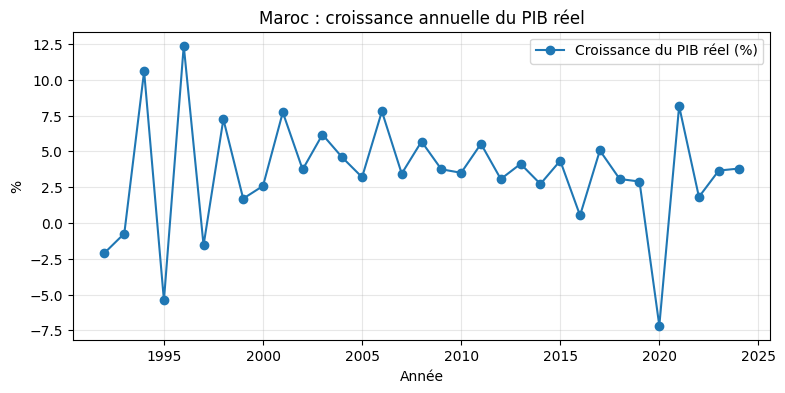

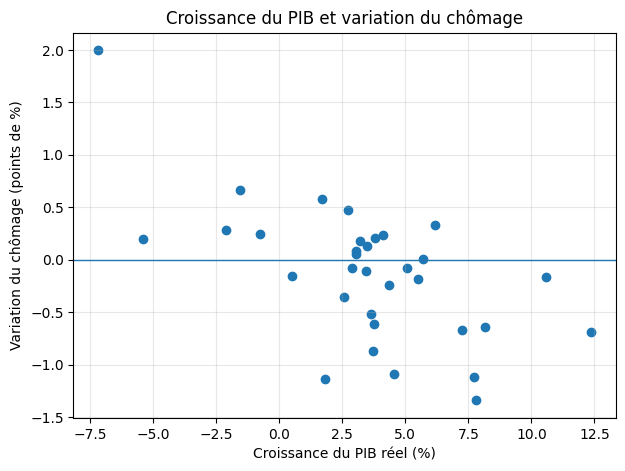

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum().to_frame("Nombre"))
print("Doublons :", df.duplicated(subset=["year"]).sum())
display(df[["gdp_growth", "unemployment", "delta_unemployment"]].describe())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df["year"], df["gdp_growth"], marker="o", label="Croissance du PIB réel (%)")
ax.set_title("Maroc : croissance annuelle du PIB réel")
ax.set_xlabel("Année")
ax.set_ylabel("%")
ax.grid(True, alpha=.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["gdp_growth"], df["delta_unemployment"])
ax.axhline(0, linewidth=1)
ax.set_title("Croissance du PIB et variation du chômage")
ax.set_xlabel("Croissance du PIB réel (%)")
ax.set_ylabel("Variation du chômage (points de %)")
ax.grid(True, alpha=.3)
plt.show()


## 2. Estimation de la régression linéaire simple

L'estimation OLS porte sur toute la période disponible. Les erreurs-types HAC (Newey–West, un retard) sont ajoutées comme contrôle de l'inférence face à une éventuelle autocorrélation/hétéroscédasticité. Le modèle reste une régression linéaire simple à un seul prédicteur.

In [4]:
X = sm.add_constant(df["gdp_growth"])
y = df["delta_unemployment"]
ols = sm.OLS(y, X).fit()
ols_hac = ols.get_robustcov_results(cov_type="HAC", maxlags=1)

print(ols.summary())
print("\\n--- Inférence avec erreurs-types HAC (Newey-West, maxlags=1) ---")
print(ols_hac.summary())

coef = pd.DataFrame({
    "Coefficient OLS": ols.params,
    "Erreur-type HAC": ols_hac.bse,
    "Statistique t HAC": ols_hac.tvalues,
    "p-value HAC": ols_hac.pvalues
})
display(coef)
print("IC 95 % HAC :")
print(ols_hac.conf_int())


                            OLS Regression Results                            
Dep. Variable:     delta_unemployment   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.381
Method:                 Least Squares   F-statistic:                     20.71
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           7.74e-05
Time:                        10:23:13   Log-Likelihood:                -23.517
No. Observations:                  33   AIC:                             51.03
Df Residuals:                      31   BIC:                             54.03
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2276      0.119      1.914      0.0

,Coefficient OLS,Erreur-type HAC,Statistique t HAC,p-value HAC
const,0.227628,0.146551,1.553231,0.130519
gdp_growth,-0.102883,0.031379,-3.278767,0.002577


IC 95 % HAC :
[[-0.07126537  0.52652111]
 [-0.16687986 -0.03888597]]


## 3. Stabilité du coefficient

Une régression glissante sur des fenêtres de 15 observations permet d'observer si le coefficient estimé varie selon la période. Cette analyse est descriptive : avec des fenêtres courtes, les estimations peuvent être imprécises.

,année_fin_fenêtre,coefficient_beta
0,2006,-0.081075
1,2007,-0.080295
2,2008,-0.076353
3,2009,-0.090894
4,2010,-0.118680
5,2011,-0.165290
6,2012,-0.172078
7,2013,-0.182670
8,2014,-0.177024
9,2015,-0.200373


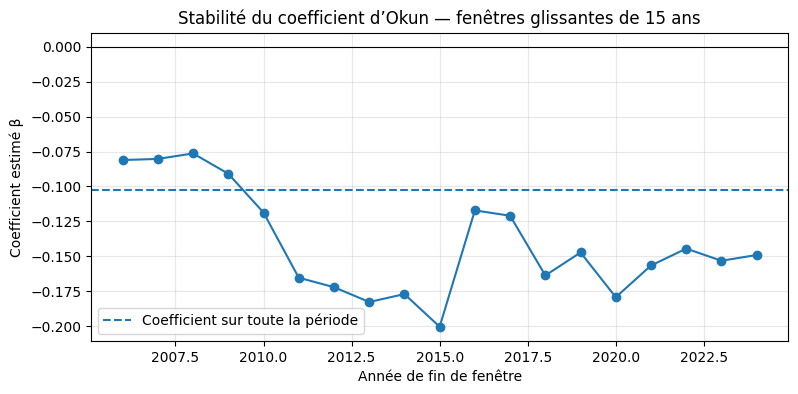

In [5]:
window = 15
rolling_years, rolling_beta = [], []
for end in range(window, len(df) + 1):
    sub = df.iloc[end-window:end]
    fit = sm.OLS(sub["delta_unemployment"], sm.add_constant(sub["gdp_growth"])).fit()
    rolling_years.append(int(sub["year"].iloc[-1]))
    rolling_beta.append(float(fit.params["gdp_growth"]))

rolling = pd.DataFrame({"année_fin_fenêtre": rolling_years, "coefficient_beta": rolling_beta})
display(rolling)

plt.figure(figsize=(9, 4))
plt.plot(rolling["année_fin_fenêtre"], rolling["coefficient_beta"], marker="o")
plt.axhline(float(ols.params["gdp_growth"]), linestyle="--", label="Coefficient sur toute la période")
plt.axhline(0, color="black", linewidth=.8)
plt.title(f"Stabilité du coefficient d’Okun — fenêtres glissantes de {window} ans")
plt.xlabel("Année de fin de fenêtre")
plt.ylabel("Coefficient estimé β")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()


## 4. Évaluation chronologique indicative

Les premières 70 % des observations servent à l'estimation et les 30 % les plus récentes au test. Ce découpage mesure la capacité prédictive hors échantillon ; il ne remplace pas l'analyse d'inférence menée sur l'ensemble de la période.

Apprentissage : 1992–2014 (23 obs.)
Test           : 2015–2024 (10 obs.)
MAE  : 0.3911 point(s) de chômage
RMSE : 0.5766 point(s) de chômage
R² test : 0.4520


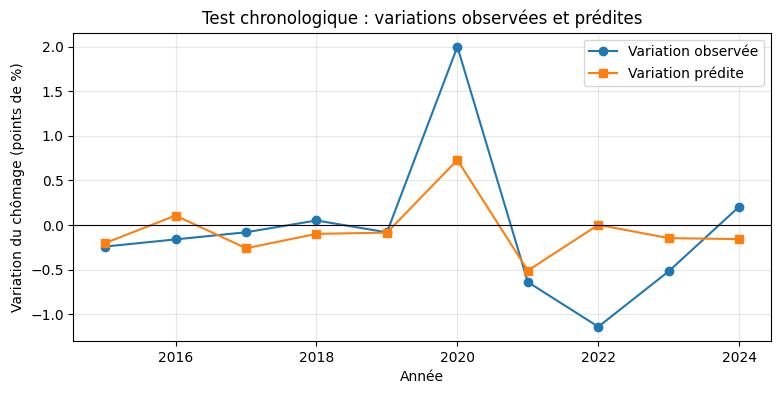

In [6]:
split = int(len(df) * 0.70)
train, test = df.iloc[:split].copy(), df.iloc[split:].copy()

model_train = sm.OLS(
    train["delta_unemployment"],
    sm.add_constant(train["gdp_growth"])
).fit()

pred = model_train.predict(sm.add_constant(test["gdp_growth"], has_constant="add"))
mae = mean_absolute_error(test["delta_unemployment"], pred)
rmse = np.sqrt(mean_squared_error(test["delta_unemployment"], pred))
r2 = r2_score(test["delta_unemployment"], pred)

print(f"Apprentissage : {train.year.min()}–{train.year.max()} ({len(train)} obs.)")
print(f"Test           : {test.year.min()}–{test.year.max()} ({len(test)} obs.)")
print(f"MAE  : {mae:.4f} point(s) de chômage")
print(f"RMSE : {rmse:.4f} point(s) de chômage")
print(f"R² test : {r2:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(test["year"], test["delta_unemployment"], marker="o", label="Variation observée")
plt.plot(test["year"], pred, marker="s", label="Variation prédite")
plt.axhline(0, color="black", linewidth=.8)
plt.title("Test chronologique : variations observées et prédites")
plt.xlabel("Année")
plt.ylabel("Variation du chômage (points de %)")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()


## 5. Interprétation automatique à compléter

- Le signe de \(\hat\beta\) indique le sens de la relation estimée.
- Une valeur négative est conforme au sens attendu par la loi d'Okun.
- La p-value HAC et l'intervalle de confiance permettent d'évaluer la significativité statistique.
- La stabilité doit être discutée à partir du graphique des coefficients glissants.
- Une association statistique ne démontre pas, à elle seule, une causalité.

**Limites :** fréquence annuelle, taille d'échantillon limitée, révisions possibles des séries, mesure du chômage modélisée par l'OIT, variables omises et spécification linéaire simple. Le modèle à un seul prédicteur ne contrôle pas les autres déterminants du chômage.

## Sources des données et références

### Données
- Banque mondiale, *GDP growth (annual %)*, indicateur `NY.GDP.MKTP.KD.ZG`, Maroc : https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG?locations=MA
- Banque mondiale, *Unemployment, total (% of total labor force) (modeled ILO estimate)*, indicateur `SL.UEM.TOTL.ZS`, Maroc : https://data.worldbank.org/indicator/SL.UEM.TOTL.ZS?locations=MA
- API officielle : https://api.worldbank.org/v2/

### Deux études liées
1. Ferroud, A., Benjouid, Z., & Dab nich i, Y. (2021). « The growth-unemployment relationship in Morocco: Theoretical test and empirical validation ». *African Scientific Journal*, 3(9), 161–199. DOI : https://doi.org/10.5281/zenodo.5796138.
2. Diri, K., & El Kamli, M. (2023). « Okun’s Law amidst Crisis: Analyzing Morocco’s Experience during COVID-19 ». *Revue Internationale de la Recherche Scientifique (Revue-IRS)*, 1(5), 876–890. DOI : https://doi.org/10.5281/zenodo.8363494.

**Note méthodologique :** ces articles emploient des méthodes et spécifications plus élaborées que la régression linéaire simple demandée ici. Ils servent de travaux liés et de points de comparaison, pas de résultats à recopier.